# 08 · Alert engine (Stage 3)
**Goal:** turn forecasts into alerts a grid operator can act on, and measure how reliable they are.

| Alert | Raised when | Scored against |
|---|---|---|
| Ramp | forecast drops > 20 % of capacity in one hour, **not** explained by the clear-sky curve | the same rule on actual output (the weather-driven ramps from EDA section 8) |
| Low output | forecast < 30 % of clear-sky output | actual output < 30 % of clear-sky output |
| Low confidence | P10–P90 width above the 90th percentile of training widths | P50 error > 2 × the model's cross-validated RMSE |
| Drift | 7-day rolling RMSE > 1.5 × cross-validated RMSE | no label; reported as days flagged |

- Forecasts come from the realistic `lagged` LightGBM models at **h = 1** (intraday) and **h = 24** (day-ahead).
- Thresholds live in `src/config.py`. They are set from training data or fixed in advance, never tuned on the test set.
- Scores use daytime test hours only.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

from io_utils import FIG, ROOT, load_processed
from config import SITES
from features import chronological_split
from models import predict_quantiles, train_from_params

PARAMS = json.load(open(ROOT / "reports" / "lgbm_params.json"))
data = {}
for s in ("primary", "site_a"):
    d = load_processed(s)
    d.attrs["tz"] = SITES[s]["tz"]
    data[s] = d
from evaluation import fit_clearsky_scale
from alerts import actual_events, raise_alerts, score, width_threshold

HORIZONS = [1, 24]

## 1. Raise alerts and score them

In [2]:
rows, store = [], {}
for s, d in data.items():
    cut = d.index[int(len(d) * 0.8)]
    scale = fit_clearsky_scale(d[d.index < cut])
    for h in HORIZONS:
        p = PARAMS[f"{s}|lagged|{h}"]
        models, X = train_from_params(d, h, "lagged", p)
        P = predict_quantiles(models, X)
        limit = width_threshold(P[P.index < cut], d["is_day"])
        A = raise_alerts(P, d, scale, limit, p["cv_rmse"])
        E = actual_events(P, d, scale, p["cv_rmse"])
        valid = (d.index >= cut) & (d["is_day"] == 1) & d["capacity_factor"].notna() & P["p50"].notna()
        valid = pd.Series(valid, index=d.index)
        for k in E:
            rows.append({"site": s, "horizon_h": h, "alert": k, **score(A[k], E[k], valid)})
        store[(s, h)] = (P, A, E, valid)

alert_results = pd.DataFrame(rows)
alert_results.round(3)

,site,horizon_h,alert,events,alerts,TP,FP,FN,precision,recall,F1
0,primary,1,ramp,27,11,0,11,27,0.000,0.000,NaN
1,primary,1,low_output,105,64,45,19,60,0.703,0.429,0.533
2,primary,1,low_confidence,159,101,41,60,118,0.406,0.258,0.315
3,primary,24,ramp,27,0,0,0,27,NaN,0.000,NaN
4,primary,24,low_output,105,0,0,0,105,NaN,0.000,NaN
5,primary,24,low_confidence,161,283,62,221,99,0.219,0.385,0.279
6,site_a,1,ramp,55,36,10,26,45,0.278,0.182,0.220
7,site_a,1,low_output,170,121,85,36,85,0.702,0.500,0.584
8,site_a,1,low_confidence,120,226,63,163,57,0.279,0.525,0.364
9,site_a,24,ramp,55,4,2,2,53,0.500,0.036,0.068


## 2. Drift monitor

In [3]:
drift_rows = []
for (s, h), (P, A, E, valid) in store.items():
    flagged = A.loc[valid, "drift"].groupby(A.loc[valid].index.date).any()
    drift_rows.append({"site": s, "horizon_h": h, "test_days": len(flagged),
                       "days_flagged": int(flagged.sum()), "share": flagged.mean()})
pd.DataFrame(drift_rows).round(3)

,site,horizon_h,test_days,days_flagged,share
0,primary,1,157,20,0.127
1,primary,24,157,27,0.172
2,site_a,1,106,4,0.038
3,site_a,24,106,0,0.000


## 3. Example: alerts on a test week (h = 1)

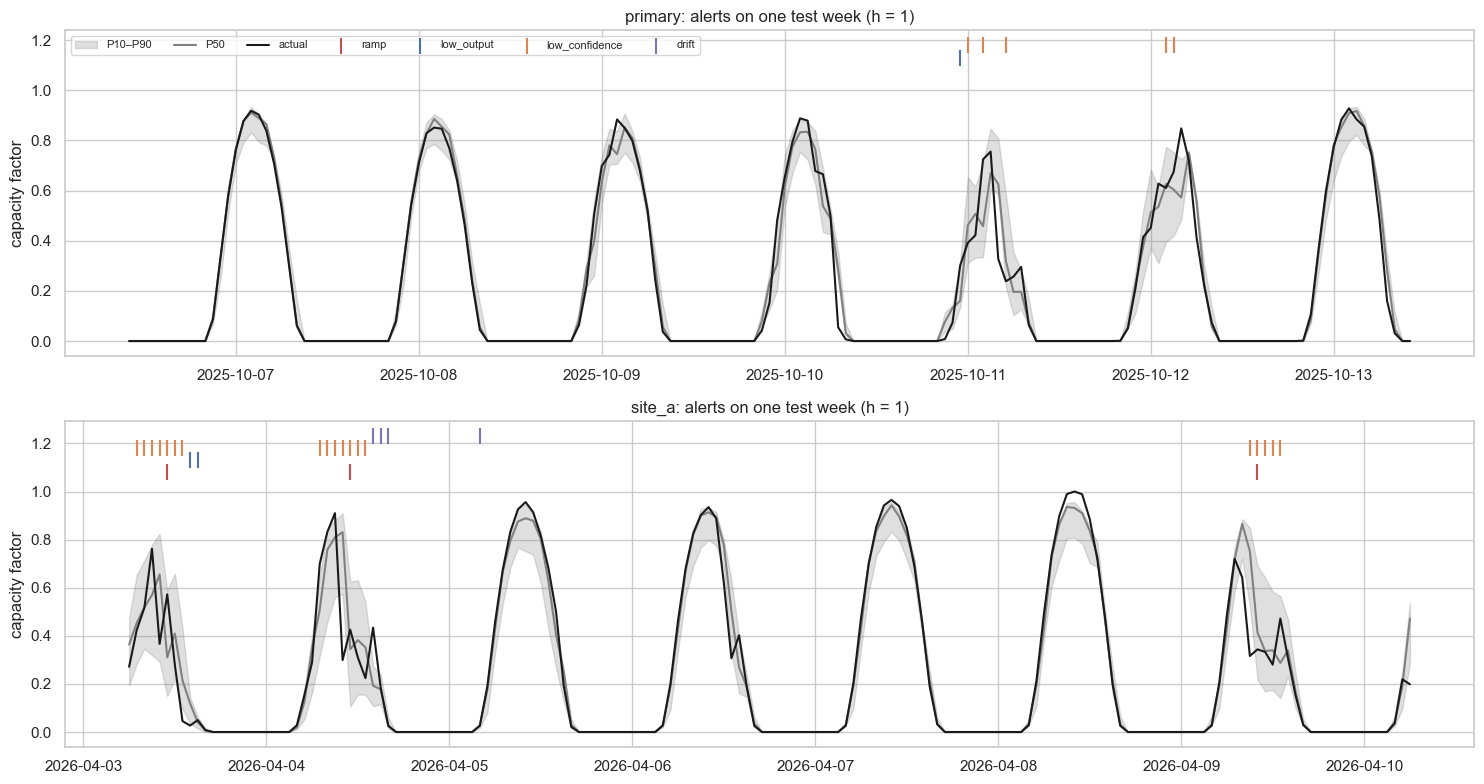

In [4]:
COLORS = {"ramp": "C3", "low_output": "C0", "low_confidence": "C1", "drift": "C4"}
fig, ax = plt.subplots(2, 1, figsize=(15, 8))
for i, s in enumerate(data):
    P, A, E, valid = store[(s, 1)]
    d = data[s]
    start = d.index[int(len(d) * 0.8)] + pd.Timedelta(days=20)
    w = slice(start, start + pd.Timedelta(days=7))
    a = ax[i]
    a.fill_between(P.loc[w].index, P.loc[w, "p10"], P.loc[w, "p90"], color="grey", alpha=.25, label="P10–P90")
    a.plot(P.loc[w].index, P.loc[w, "p50"], color="grey", label="P50")
    a.plot(d.loc[w].index, d.loc[w, "capacity_factor"], color="k", lw=1.5, label="actual")
    for j, (k, c) in enumerate(COLORS.items()):
        t = A.loc[w].index[A.loc[w, k]]
        a.scatter(t, np.full(len(t), 1.08 + 0.05 * j), marker="|", s=120, color=c, label=k)
    a.set_title(f"{s}: alerts on one test week (h = 1)"); a.set_ylabel("capacity factor")
ax[0].legend(fontsize=8, ncol=7)
fig.tight_layout(); fig.savefig(FIG / "17_alerts_example_week.png", dpi=120); plt.show()

In [5]:
alert_results.round(5).to_csv(ROOT / "reports" / "alert_results.csv", index=False)
print("saved reports/alert_results.csv")

saved reports/alert_results.csv


## Findings
1. **The low-output alert is the most useful one.** At h = 1 it has precision **0.70** on both sites and recall of 0.43 (primary) and 0.50 (Site A), so 7 out of 10 alerts are correct. At h = 24 it almost never fires, because without weather forecasts the model cannot tell a dull day from a normal one 24 hours ahead.
2. **Weather-driven ramps are hard to see coming from past output alone.** Site A at h = 1 achieves F1 0.22 (10 of 55 ramps caught), and the primary site catches none of its 27. These ramps come from passing clouds, which the `lagged` inputs cannot anticipate. A ramp alert of practical use needs NWP or sky-camera/satellite inputs. This answers the alert research question honestly.
3. **The low-confidence alert works modestly** (F1 0.28–0.36). Its recall is 0.26–0.52, which means wide intervals do pick out many of the large errors. Its precision is low, which is consistent with the intervals being miscalibrated (notebook 05, finding 4).
4. **The drift monitor flagged 13–17 % of test days on the primary site, 4 % on Site A at h = 1, and none on Site A at h = 24.** Errors on the test set therefore stay mostly within their cross-validation level, and there are no signs of a degrading model.
5. **For the dashboard:** show the low-output and low-confidence alerts at intraday horizons, and label the ramp alert as experimental.